In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

print("Modeling and regularized regression libraries loaded.")


Modeling and regularized regression libraries loaded.


In [2]:
df = pd.read_csv("womens_clothing_regression_dataset.csv")
print(f"Dataset shape: {df.shape}")

df['Inter_App_x_Tenure'] = df['Time_on_App'] * df['Length_of_Membership']
df['Inter_Orders_x_AOV'] = df['Annual_Orders'] * df['Avg_Order_Value']

candidate_features = [
    'Length_of_Membership',
    'Time_on_App',
    'Avg_Session_Length',
    'Time_on_Website',
    'Annual_Orders',
    'Avg_Order_Value',
    'Age',
    'Rating',
    'Recommended IND',
    'Positive Feedback Count',
    'Review_Length',
    'Inter_App_x_Tenure',
    'Inter_Orders_x_AOV'
]
target = 'Yearly_Amount_Spent'

X = df[candidate_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_train)
X_te_sc = scaler.transform(X_test)

print(f"Standardized features matrix shape: {X_tr_sc.shape}")


Dataset shape: (23465, 20)
Standardized features matrix shape: (18772, 13)


In [3]:
df_traj = pd.read_csv("ridge_lasso_alpha_tuning_trajectory.csv")
print("Cross-Validation Performance Across Regularization Strength (Sample Alphas):")
df_traj.head(10)


Cross-Validation Performance Across Regularization Strength (Sample Alphas):


,Alpha,Log10_Alpha,Ridge_CV_R2,Ridge_CV_RMSE,Lasso_CV_R2,Lasso_CV_RMSE
0,0.001000,-3.00,0.9646,27.42,0.9646,27.42
1,0.001778,-2.75,0.9646,27.42,0.9646,27.42
2,0.003162,-2.50,0.9646,27.42,0.9646,27.42
3,0.005623,-2.25,0.9646,27.42,0.9646,27.42
4,0.010000,-2.00,0.9646,27.42,0.9646,27.42
5,0.017783,-1.75,0.9646,27.42,0.9646,27.42
6,0.031623,-1.50,0.9646,27.42,0.9646,27.42
7,0.056234,-1.25,0.9646,27.42,0.9646,27.41
8,0.100000,-1.00,0.9646,27.42,0.9646,27.41
9,0.177828,-0.75,0.9646,27.42,0.9646,27.42


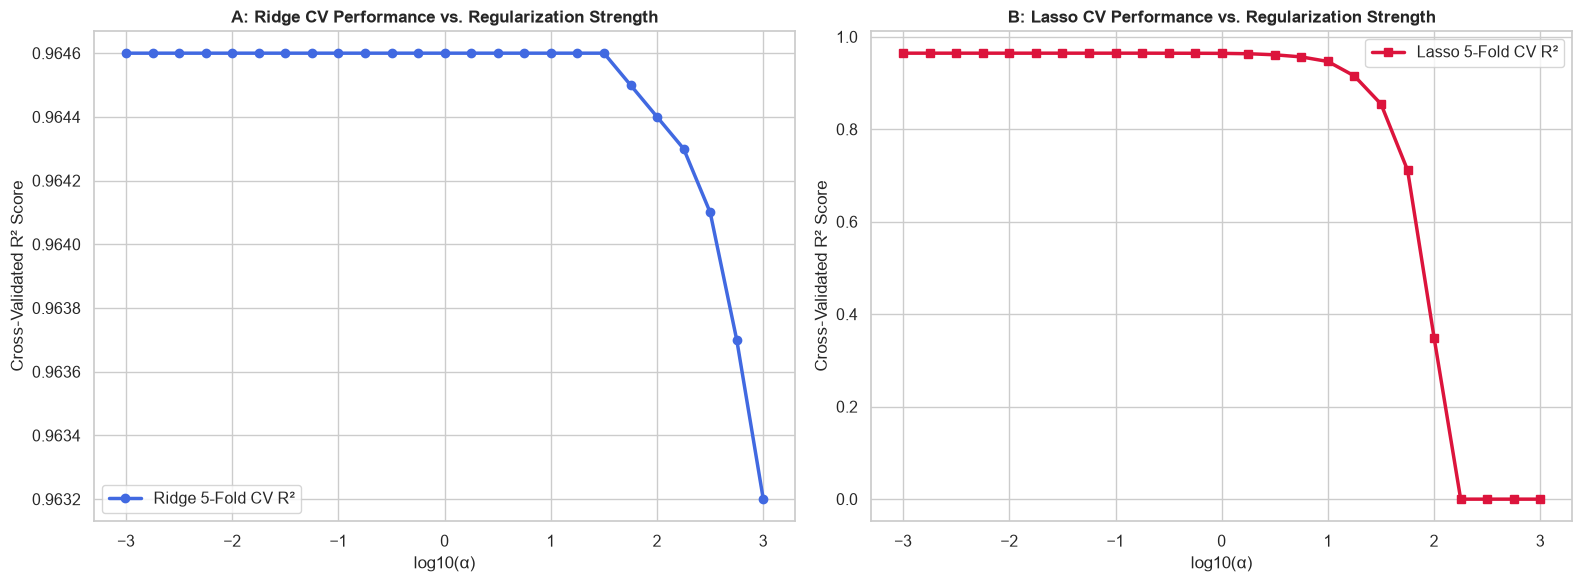

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(df_traj['Log10_Alpha'], df_traj['Ridge_CV_R2'], marker='o', color='royalblue', linewidth=2.5, label='Ridge 5-Fold CV R²')
axes[0].set_title("A: Ridge CV Performance vs. Regularization Strength", fontweight='bold')
axes[0].set_xlabel("log10(α)")
axes[0].set_ylabel("Cross-Validated R² Score")
axes[0].legend()

axes[1].plot(df_traj['Log10_Alpha'], df_traj['Lasso_CV_R2'], marker='s', color='crimson', linewidth=2.5, label='Lasso 5-Fold CV R²')
axes[1].set_title("B: Lasso CV Performance vs. Regularization Strength", fontweight='bold')
axes[1].set_xlabel("log10(α)")
axes[1].set_ylabel("Cross-Validated R² Score")
axes[1].legend()

plt.tight_layout()
plt.savefig("cv_error_vs_alpha_tuning_curves.png", dpi=300)
plt.show()


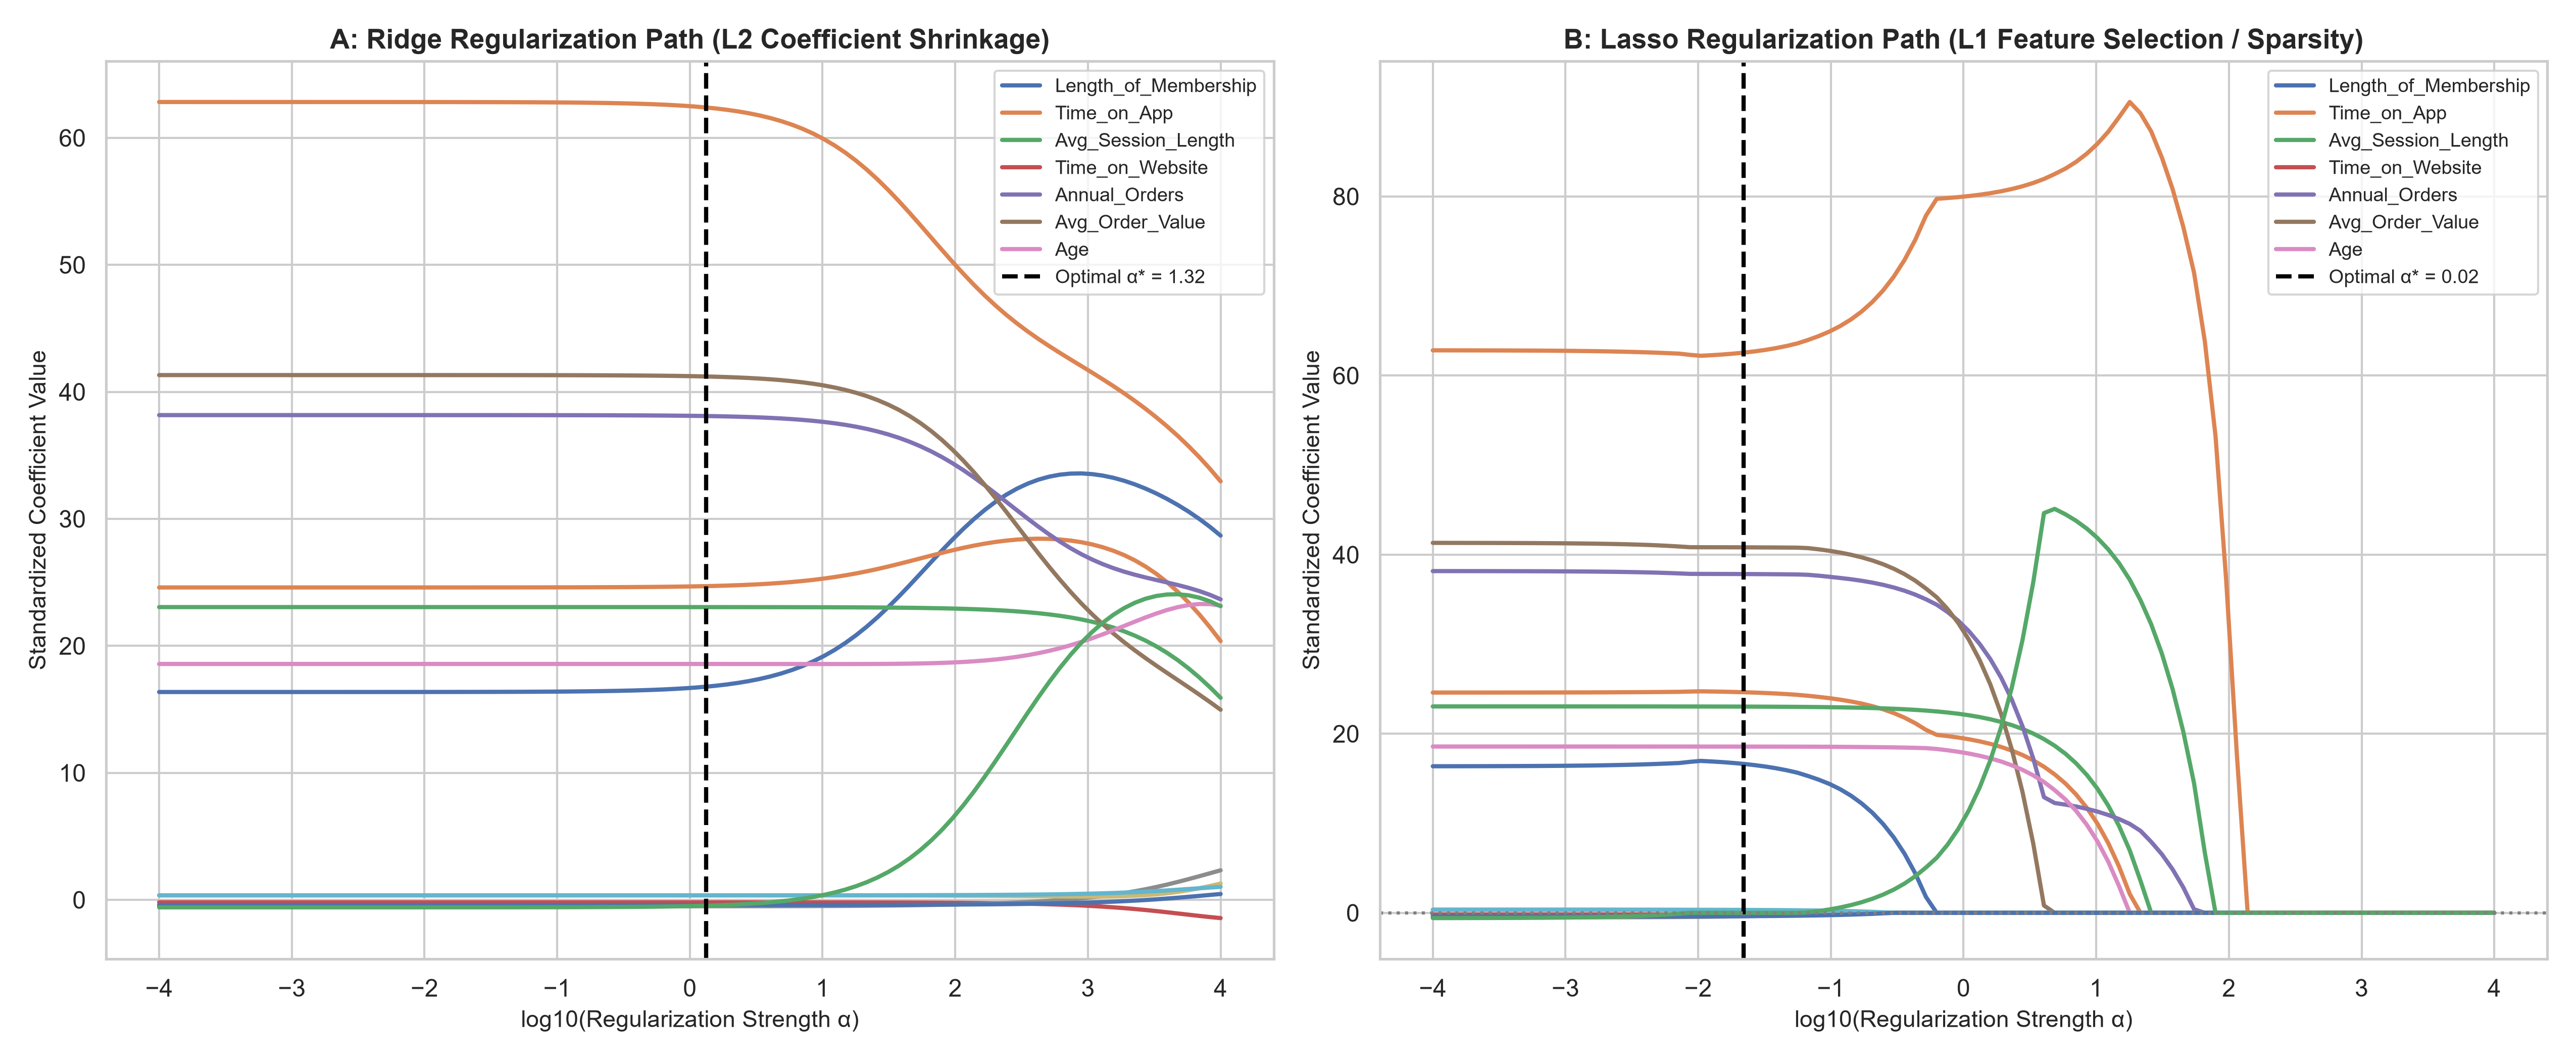

In [5]:
# Display regularization paths figure
from IPython.display import Image
Image(filename="regularization_paths_ridge_vs_lasso.png")


In [6]:
df_sparsity = pd.read_csv("feature_shrinkage_and_sparsity_schedule.csv")
df_sparsity


,Feature,Optimal_Ridge_Coef,Optimal_Lasso_Coef,Lasso_Status,Lasso_Elimination_Alpha,Shrinkage_Behavior
0,Inter_App_x_Tenure,62.3944,62.5606,Retained (Active),138.4886,Pruned at α ≈ 1.38e+02
1,Avg_Order_Value,41.2121,40.8170,Retained (Active),4.8626,Pruned at α ≈ 4.86e+00
2,Annual_Orders,38.0967,37.8348,Retained (Active),65.7933,Pruned at α ≈ 6.58e+01
3,Time_on_App,24.7020,24.6378,Retained (Active),21.5443,Pruned at α ≈ 2.15e+01
4,Avg_Session_Length,23.0502,23.0324,Retained (Active),25.9502,Pruned at α ≈ 2.60e+01
5,Age,18.5724,18.5664,Retained (Active),17.8865,Pruned at α ≈ 1.79e+01
6,Length_of_Membership,16.7827,16.6324,Retained (Active),0.6280,Pruned at α ≈ 6.28e-01
7,Positive Feedback Count,0.3510,0.3250,Retained (Active),0.3594,Pruned at α ≈ 3.59e-01
8,Recommended IND,0.3560,0.2483,Retained (Active),0.0811,Pruned at α ≈ 8.11e-02
9,Inter_Orders_x_AOV,-0.4617,0.0000,Eliminated (Zero Weight),0.0087,Pruned at α ≈ 8.70e-03


In [7]:
df_perf = pd.read_csv("optimal_models_performance_comparison.csv")
df_perf


,Model_Architecture,Optimal_Alpha,Active_Features,Training_R2,Test_R2,Test_RMSE,Test_MAE,Train_Test_Gap,Sparsity_Property
0,Unregularized OLS,0.0000,13 / 13,0.9647,0.9653,27.34,21.72,-0.0007,None (Unpenalized OLS)
1,Ridge Regression (α=1.322),1.3219,13 / 13,0.9647,0.9653,27.34,21.72,-0.0007,Dense (L2 weight decay)
2,Lasso Regression (α=0.022),0.0221,12 / 13,0.9647,0.9653,27.34,21.72,-0.0007,Sparse (L1 variable selection)


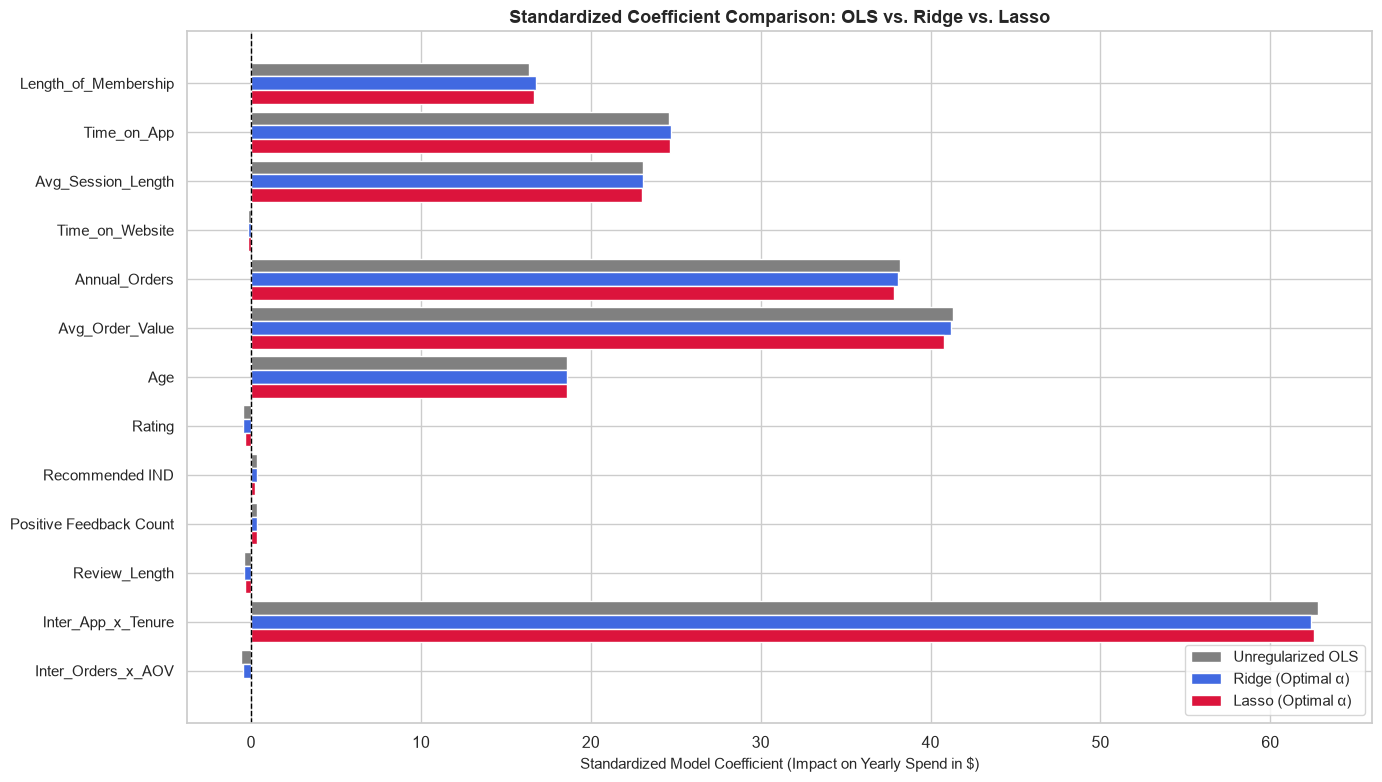

In [8]:
fig, ax = plt.subplots(figsize=(14, 8))

df_coef = pd.read_csv("coefficient_comparison_ols_ridge_lasso.csv")
x = np.arange(len(df_coef))
width = 0.28

ax.barh(x - width, df_coef['OLS_Coefficient'], width, label='Unregularized OLS', color='gray')
ax.barh(x, df_coef['Ridge_Optimal_Coef'], width, label='Ridge (Optimal α)', color='royalblue')
ax.barh(x + width, df_coef['Lasso_Optimal_Coef'], width, label='Lasso (Optimal α)', color='crimson')

ax.set_yticks(x)
ax.set_yticklabels(df_coef['Feature'], fontsize=11)
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set_title("Standardized Coefficient Comparison: OLS vs. Ridge vs. Lasso", fontweight='bold', fontsize=13)
ax.set_xlabel("Standardized Model Coefficient (Impact on Yearly Spend in $)", fontsize=11)
ax.legend(loc='lower right', fontsize=11)
ax.invert_yaxis()

plt.tight_layout()
plt.savefig("coefficient_comparison_bar_plot.png", dpi=300)
plt.show()


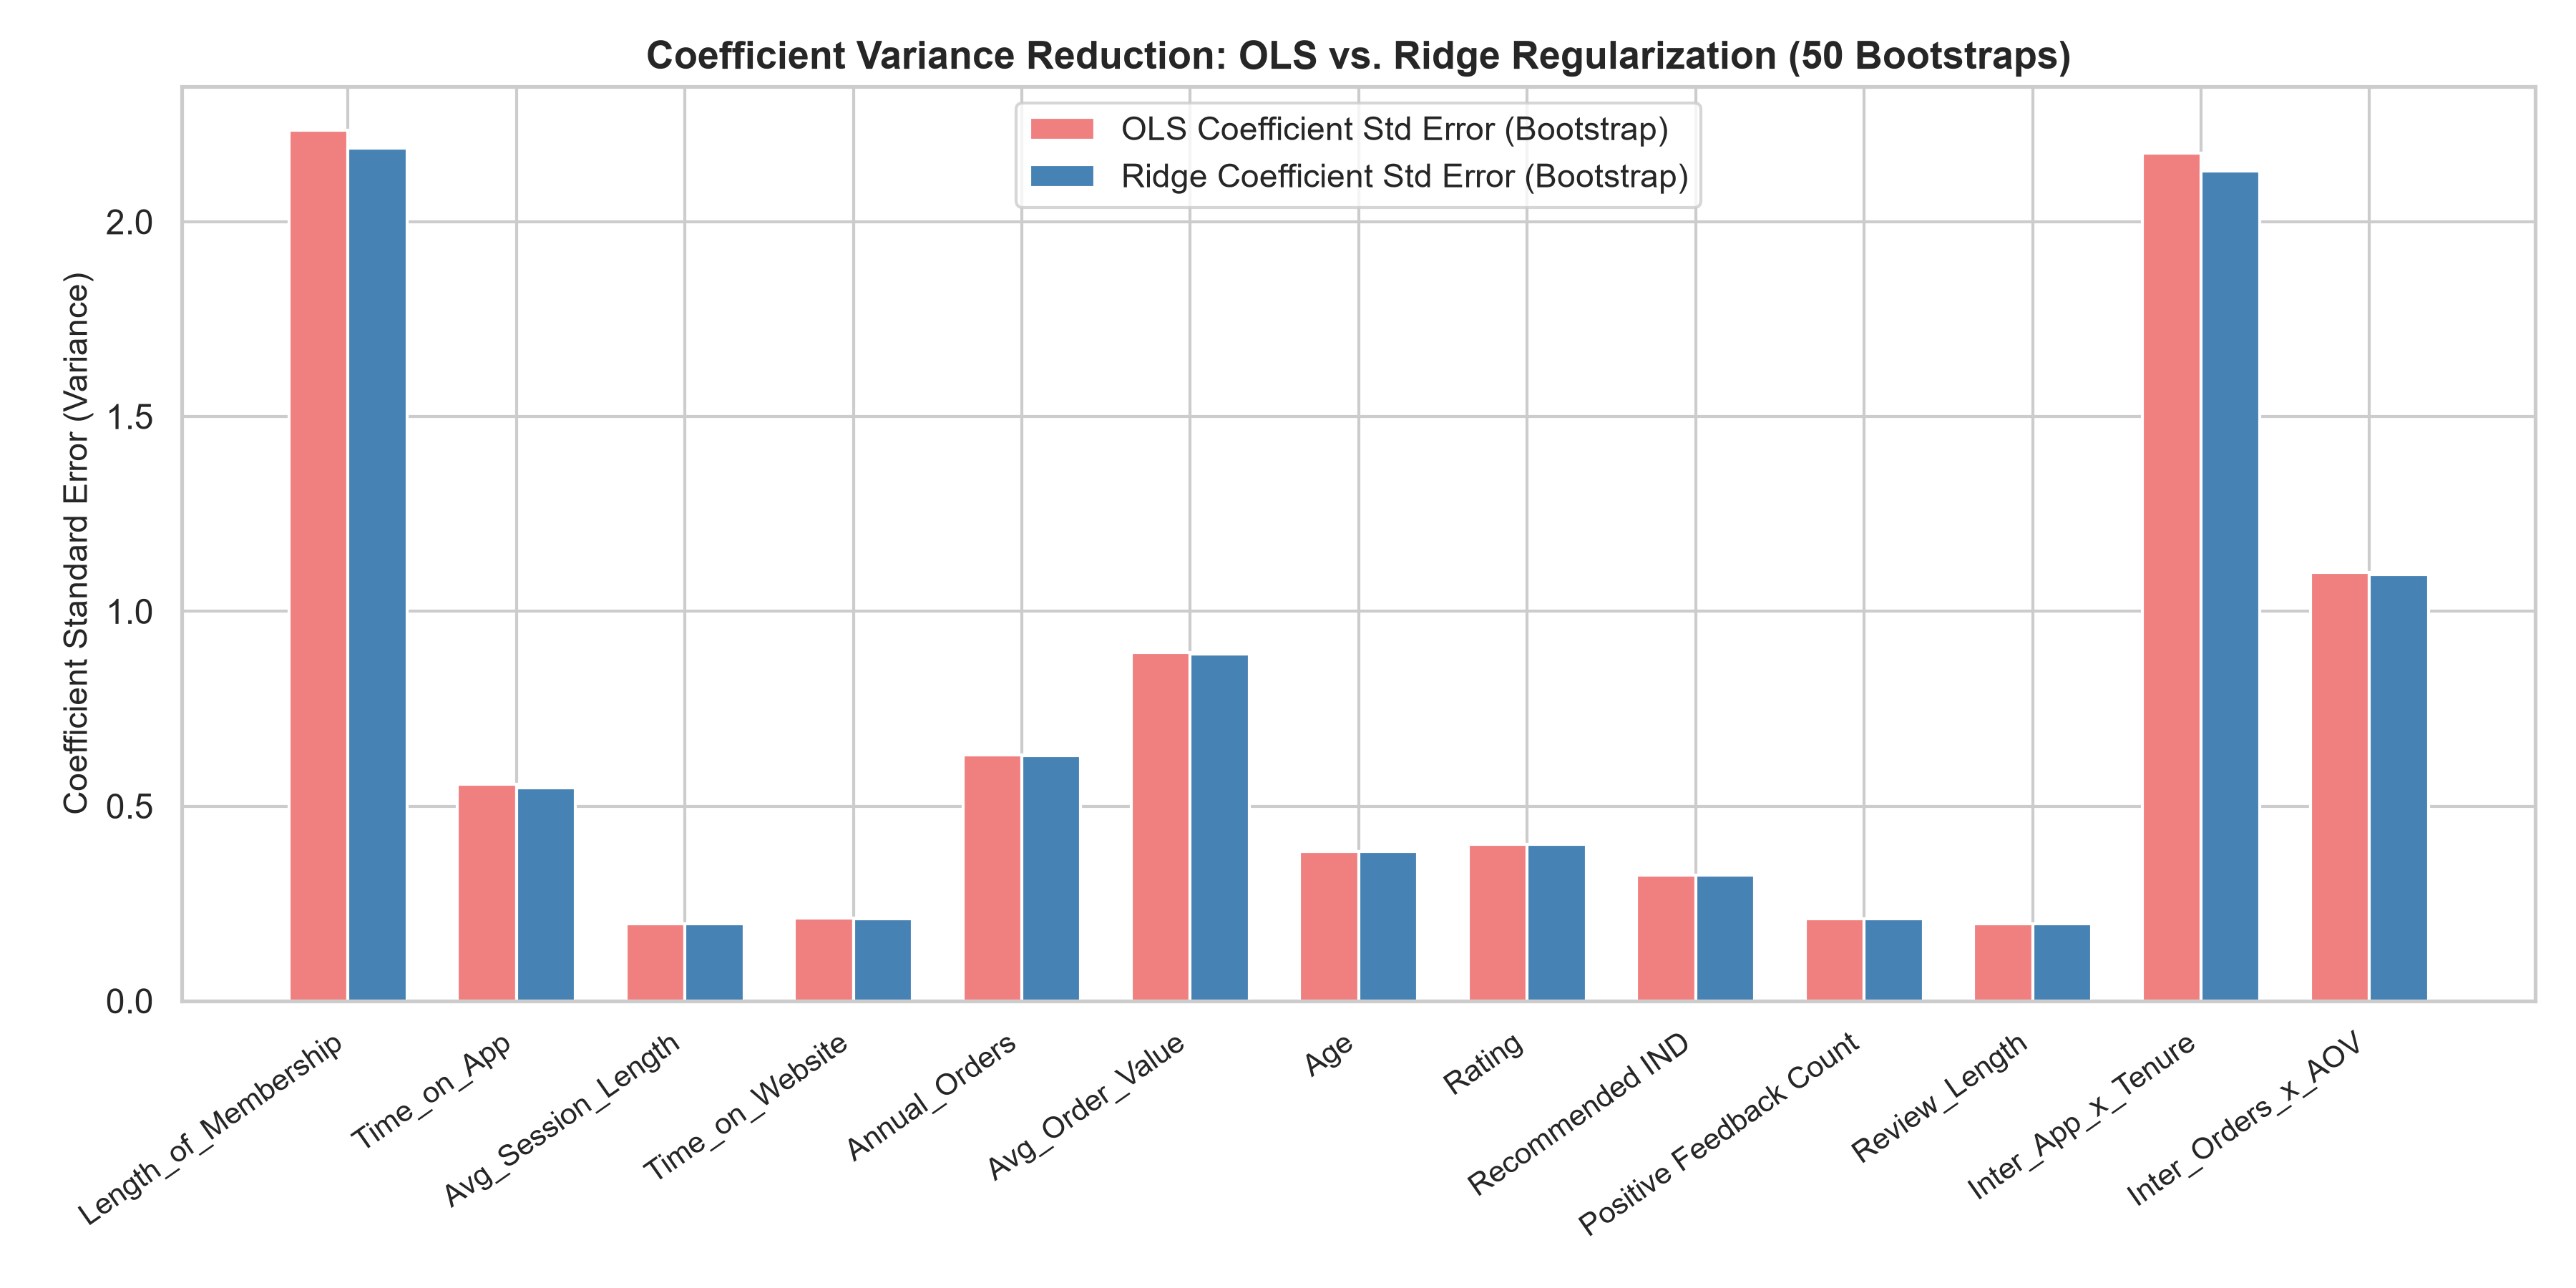

In [9]:
Image(filename="coefficient_stability_bootstrap_distributions.png")
